In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import h5py
import math
import cv2
import torch
from snntorch import spikegen
import os
from lightglue import viz2d
from lightglue import LightGlue, SuperPoint, DISK
from lightglue.utils import numpy_image_to_torch, rbd


### Select candidate frames for homography

In [ ]:
clip_path = "week_32/box_3/2024_08_06_16_52_08_recordings/event_frames/clip_002_frames.h5"

with h5py.File(clip_path, "r") as f:
    frames = f["frames"][:]

activity = frames.reshape(frames.shape[0], -1).sum(axis=1)

In [4]:
def spatial_entropy(frame, grid=(10, 10), normalize=True):
    frame = np.asarray(frame)
    h, w = frame.shape
    gh, gw = grid

    ys = np.linspace(0, h, gh + 1, dtype=int)
    xs = np.linspace(0, w, gw + 1, dtype=int)

    # sum activity in each cell
    cell_counts = []
    for i in range(gh):
        for j in range(gw):
            cell = frame[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            cell_counts.append(cell.sum())

    cell_counts = np.asarray(cell_counts, dtype=float)
    total = cell_counts.sum()

    if total == 0:
        return 0.0, cell_counts

    # probability distribution over cells
    p = cell_counts / total
    p = p[p > 0]  # avoid log(0)

    H = -(p * np.log2(p)).sum()

    if normalize:
        H_max = np.log2(gh * gw)
        H = H / H_max if H_max > 0 else 0.0

    return float(H), cell_counts

In [5]:
candidates = []

for i in range(len(frames)):
    a = activity[i]/frames[0].size
    if  a > 0.1 and a < 0.4:
        entropy, counts = spatial_entropy(frames[i], (16, 16))
        if entropy > 0.85 and entropy < 0.96:
            candidates.append({"frame": frames[i], "idx": i, "activity": a, "entropy": entropy})

print(f"Found {len(candidates)} candidate frames")

Found 21 candidate frames


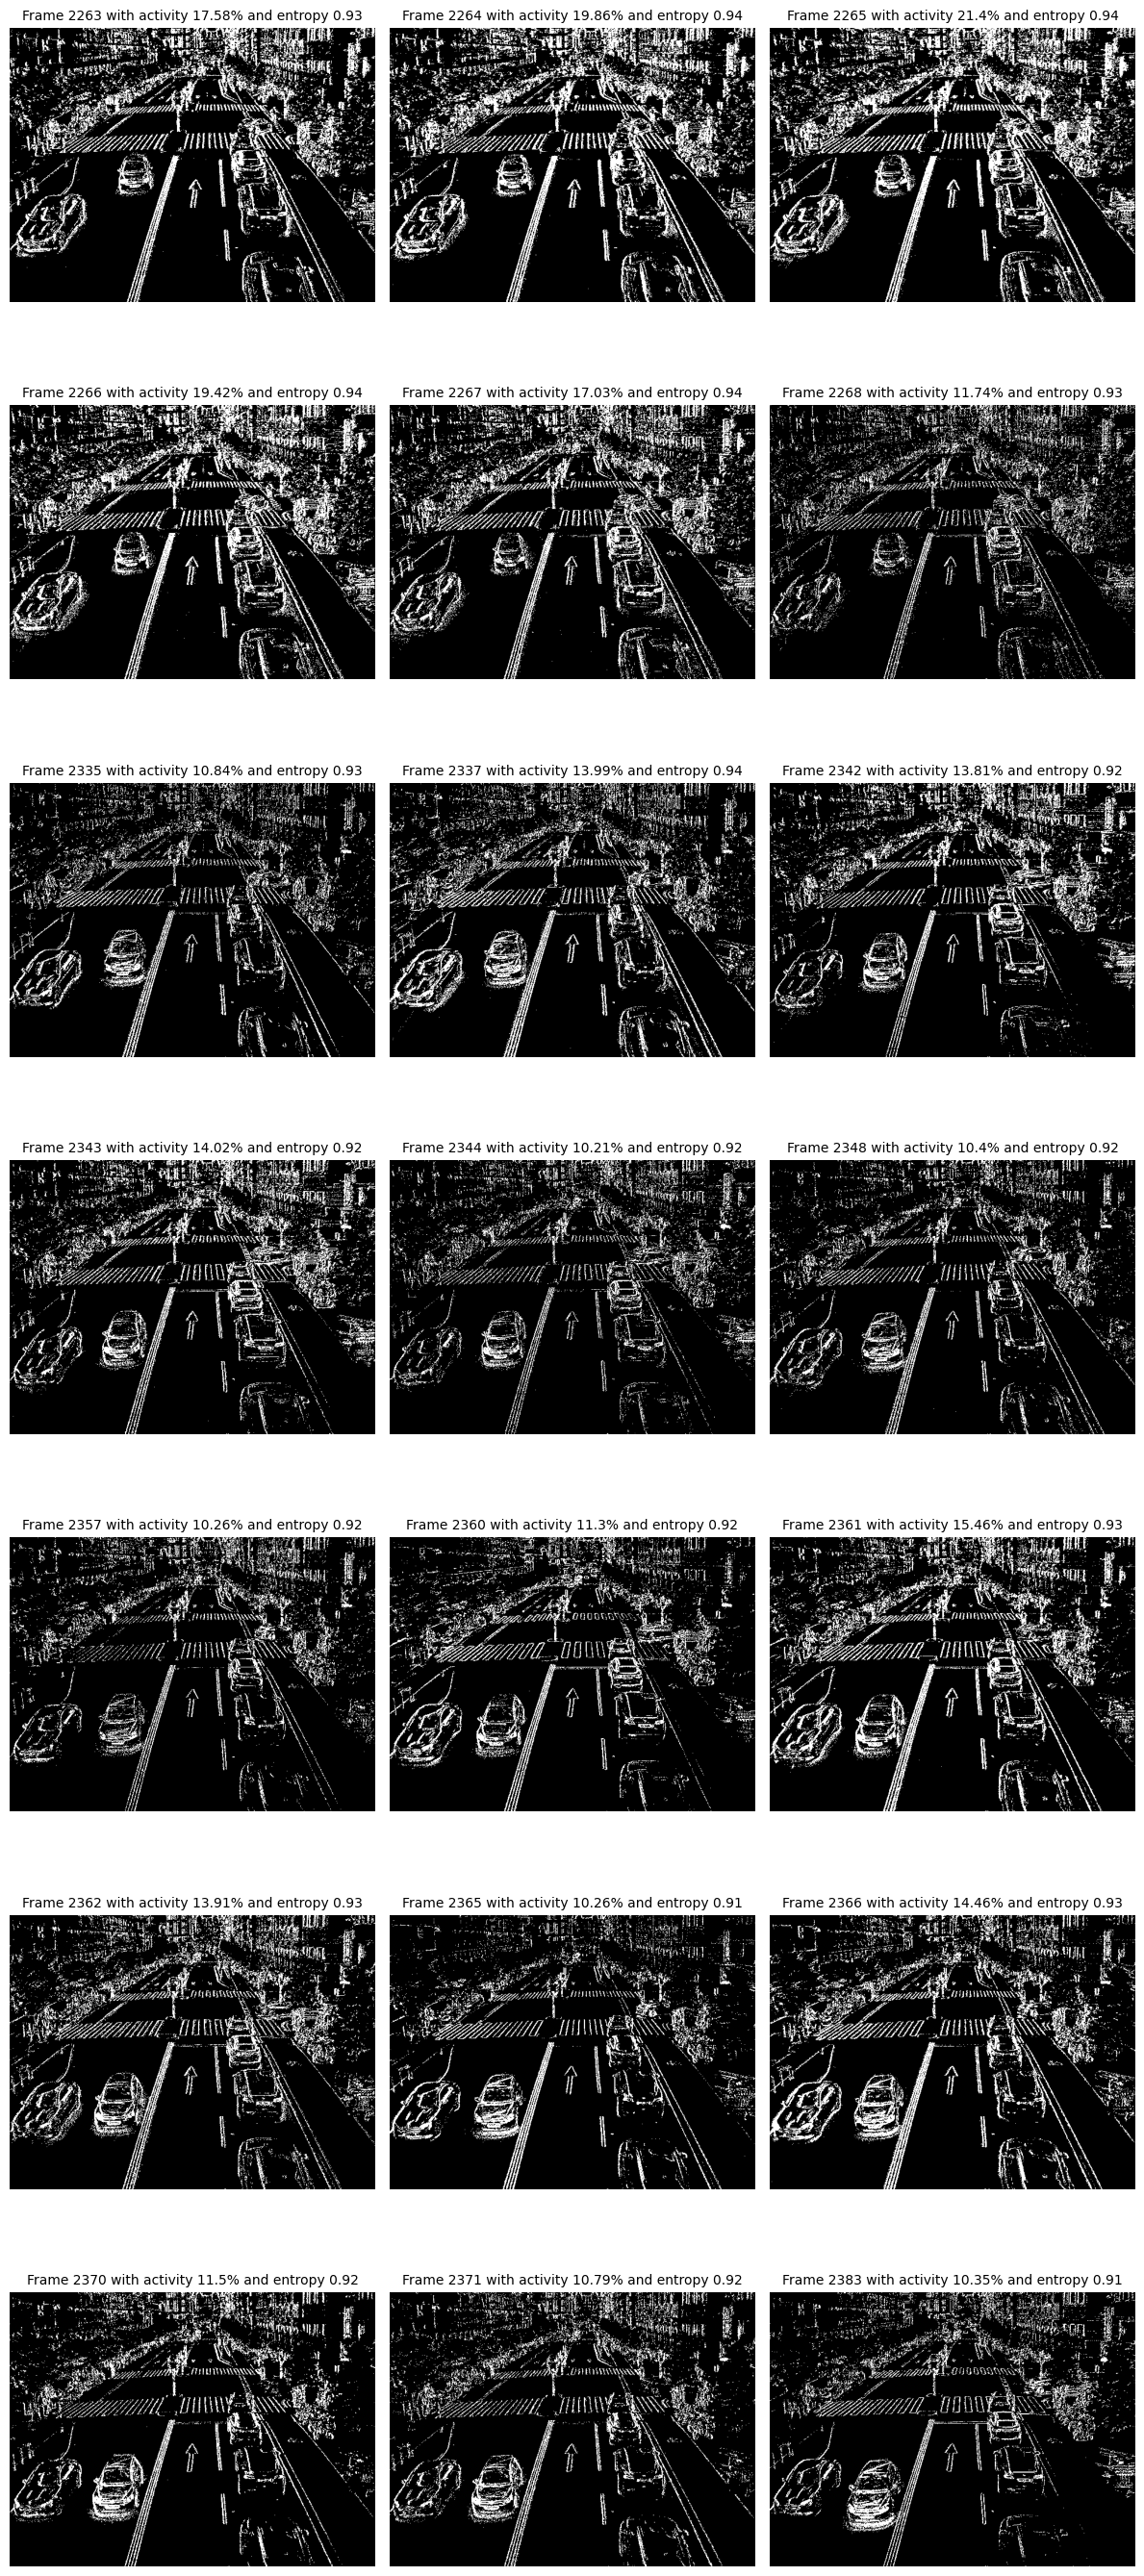

In [6]:
n = len(candidates)
cols = 3
n = np.min((21,n))
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(rows * cols):
    ax = axes[i]

    if i < n:
        fm = candidates[i]
        ax.imshow(fm["frame"], cmap='gray')
        ax.set_title(f"Frame {fm['idx']} with activity {round(fm['activity']*100,2)}% and entropy {round(fm['entropy'],2)}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [7]:
k = 5

top_indices = np.argsort(activity)[-k:][::-1]  # descending order
top_frames = frames[top_indices]

print("Top indices:", top_indices)
print("Top activities:", activity[top_indices])

Top indices: [2265 2264 2266 2263 2267]
Top activities: [65736 61004 59660 54012 52305]


In [8]:
c = 1
for i in top_indices:
    entropy, counts = spatial_entropy(frames[i], (16, 16))
    print(f"{c}. Activity: {round(counts.sum()/frames[0].size*100, 2)}%, Entropy: {round(entropy,3)}, Frame nbr: {i}")
    c += 1

1. Activity: 21.4%, Entropy: 0.94, Frame nbr: 2265
2. Activity: 19.86%, Entropy: 0.939, Frame nbr: 2264
3. Activity: 19.42%, Entropy: 0.939, Frame nbr: 2266
4. Activity: 17.58%, Entropy: 0.934, Frame nbr: 2263
5. Activity: 17.03%, Entropy: 0.937, Frame nbr: 2267


### Test build homography for evaluation

In [ ]:
video_path = "//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_32/box_3/2024_08_06_16_52_08_recordings/video.avi"
timestamp_path = "//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_32/box_3/2024_08_06_16_52_08_recordings/timestamps.csv"
out_path = "week_32/box_3/2024_08_06_16_52_08_recordings/homography.npz"

In [10]:
df_timestamps = pd.read_csv(timestamp_path)
SHIFT = df_timestamps.index[df_timestamps["event_time"] != 0][0]

In [11]:
cfg = {
    "extractor": "SuperPoint",
    "device": "cpu",   # change to "cuda" if available
    "max_kpts": 4096,
    "homography": {
        "method": cv2.RANSAC,
        "ransacReprojThreshold": 3.0,
    }
}

In [12]:
def extract_clip_id(filename: str):
    # Extract clip id like 'clip_000' from filename
    m = re.search(r"(clip_\d{3})", filename)
    return m.group(1) if m else None


def event_to_gray_uint8(img):
    img = np.asarray(img, np.float32)
    img -= img.min()
    mx = img.max()
    if mx > 0:
        img *= 255.0 / mx
    return img.astype(np.uint8)


def load_frame(path: str):
    ext = os.path.splitext(path)[1].lower()

    if ext == ".npy":
        return np.load(path)

    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise RuntimeError(f"Could not read file: {path}")

    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    return img


def preprocess_lightglue(img):
    img = event_to_gray_uint8(img)
    return numpy_image_to_torch(img)


def build_lightglue_models(cfg):
    device = cfg["device"]

    if cfg["extractor"] == "SuperPoint":
        extractor = SuperPoint(max_num_keypoints=cfg["max_kpts"]).eval().to(device)
        matcher = LightGlue(features="superpoint").eval().to(device)
    elif cfg["extractor"] == "DISK":
        extractor = DISK(max_num_keypoints=cfg["max_kpts"]).eval().to(device)
        matcher = LightGlue(features="disk").eval().to(device)
    else:
        raise ValueError(f"Unknown extractor: {cfg['extractor']}")

    return extractor, matcher


@torch.inference_mode()
def match_lightglue(img0, img1, extractor, matcher, device="cpu"):
    img0 = preprocess_lightglue(img0).to(device)
    img1 = preprocess_lightglue(img1).to(device)

    feats0 = extractor.extract(img0)
    feats1 = extractor.extract(img1)

    matches01 = matcher({"image0": feats0, "image1": feats1})
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]

    kpts0 = feats0["keypoints"]
    kpts1 = feats1["keypoints"]
    matches = matches01["matches"]

    points0 = kpts0[matches[:, 0]]
    points1 = kpts1[matches[:, 1]]

    return {
        "points0": points0,
        "points1": points1,
        "matches": matches,
        "kpts0": kpts0,
        "kpts1": kpts1,
        "matches01": matches01,
    }

def visualize_lightglue(img0, img1, points0, points1, kpts0, kpts1, matches01, **kwargs):
    axes = viz2d.plot_images([img0, img1])
    viz2d.plot_matches(points0, points1, color='lime', lw=0.2)
    viz2d.add_text(0, f'Stop after {matches01["stop"]} layers', fs=20)

    kpc0, kpc1 = viz2d.cm_prune(matches01['prune0']), viz2d.cm_prune(matches01['prune1'])
    viz2d.plot_images([img0, img1])
    viz2d.plot_keypoints([kpts0, kpts1], colors=[kpc0, kpc1], ps=10)


def homography_from_matches(results, cfg):
    pts0 = results["points0"]
    pts1 = results["points1"]

    if torch.is_tensor(pts0):
        pts0 = pts0.detach().cpu().numpy()
    if torch.is_tensor(pts1):
        pts1 = pts1.detach().cpu().numpy()

    pts0 = np.asarray(pts0, dtype=np.float32).reshape(-1, 2)
    pts1 = np.asarray(pts1, dtype=np.float32).reshape(-1, 2)

    if len(pts0) < 4:
        return None, None, pts0, pts1

    H, mask = cv2.findHomography(
        pts0,
        pts1,
        method=cfg["homography"]["method"],
        ransacReprojThreshold=cfg["homography"]["ransacReprojThreshold"],
    )
    return H, mask, pts0, pts1


def save_homography_result(out_path, H, mask, pts0, pts1, proxy_path, event_path, clip_id):
    np.savez_compressed(
        out_path,
        H=np.array([]) if H is None else H.astype(np.float32),
        inlier_mask=np.array([]) if mask is None else mask.astype(np.uint8),
        points0=pts0.astype(np.float32),
        points1=pts1.astype(np.float32),
        num_matches=np.array([len(pts0)], dtype=np.int32),
        num_inliers=np.array([0 if mask is None else int(mask.ravel().sum())], dtype=np.int32),
        clip_id=np.array([clip_id]),
        proxy_path=np.array([proxy_path]),
        event_path=np.array([event_path]),
    )

def collect_pairs_by_clip(proxy_dir, event_dir):
    proxy_by_clip = {}
    event_by_clip = {}

    for f in os.listdir(proxy_dir):
        full = os.path.join(proxy_dir, f)
        if not os.path.isfile(full):
            continue
        clip_id = extract_clip_id(f)
        if clip_id is None:
            continue
        proxy_by_clip.setdefault(clip_id, []).append(full)

    for f in os.listdir(event_dir):
        full = os.path.join(event_dir, f)
        if not os.path.isfile(full):
            continue
        clip_id = extract_clip_id(f)
        if clip_id is None:
            continue
        event_by_clip.setdefault(clip_id, []).append(full)

    common_clips = sorted(
        set(proxy_by_clip.keys()) & set(event_by_clip.keys()),
        key=lambda x: int(re.search(r"\d+", x).group())
    )

    pairs = []
    for clip_id in common_clips:
        proxy_files = sorted(proxy_by_clip[clip_id])
        event_files = sorted(event_by_clip[clip_id])

        if len(proxy_files) != 1:
            print(f"Skipping {clip_id}: expected 1 proxy frame, found {len(proxy_files)}")
            continue

        if len(event_files) != 1:
            print(f"Skipping {clip_id}: expected 1 extracted event frame, found {len(event_files)}")
            continue

        pairs.append((clip_id, proxy_files[0], event_files[0]))

    return pairs

In [13]:
candidate_idx = [candidate["idx"] for candidate in candidates]

In [15]:
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video_path}")

top_set = set(int(i) for i in candidate_idx)

video_frames = []
frame_dict = {}
prev_frame_dict = {}
spike_dict = {}

# Prime first frame
ret, frame = cap.read()
if not ret:
    raise RuntimeError("Empty video")

prev_gray = None
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

t = 0

while t < (SHIFT + 5400*2):
    ret, frame = cap.read()
    t += 1

i = 0

while True:
    # Read next frame ONCE per iteration
    ret, next_frame = cap.read()
    if not ret:
        break

    next_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

    video_frames.append(next_gray)

    if i in top_set:
        frame_dict[i] = frame.copy()

        if prev_gray is None:
            prev_frame_dict[i] = None
            spike_dict[i] = None
        else:
            prev_frame_dict[i] = prev_gray.copy()

            data = torch.from_numpy(
                np.stack([prev_gray, gray, next_gray], axis=0)
            ).to(torch.float32)

            spikes = spikegen.delta(data, threshold=8)
            sp = spikes[1:].cpu().numpy() if torch.is_tensor(spikes) else spikes

            spike_dict[i] = (sp > 0).any(axis=0).astype(np.uint8)

        if len(frame_dict) == len(top_set):
            break

    # Shift window forward
    prev_gray = gray
    gray = next_gray
    frame = next_frame
    i += 1

cap.release()

In [17]:
extractor, matcher = build_lightglue_models(cfg)

for idx in candidate_idx:
    print(f"Processing {idx}")

    proxy_img = event_to_gray_uint8(spike_dict[idx])
    event_img = event_to_gray_uint8(frames[idx])

    results = match_lightglue(
        proxy_img,
        event_img,
        extractor=extractor,
        matcher=matcher,
        device=cfg["device"],
    )

    print(f"matches={len(results['matches'])}, out of total features={results['kpts1'].shape[0]}")

Processing 2263
matches=1244, out of total features=2671
Processing 2264
matches=1212, out of total features=2706
Processing 2265
matches=1278, out of total features=2824
Processing 2266
matches=1226, out of total features=2773
Processing 2267
matches=1170, out of total features=2851
Processing 2268
matches=1237, out of total features=2957
Processing 2335
matches=1283, out of total features=2680
Processing 2337
matches=1318, out of total features=2824
Processing 2342
matches=1343, out of total features=2743
Processing 2343
matches=1309, out of total features=2764
Processing 2344
matches=1286, out of total features=2825
Processing 2348
matches=1332, out of total features=2708
Processing 2357
matches=1339, out of total features=2602
Processing 2360
matches=1407, out of total features=2649
Processing 2361
matches=1362, out of total features=2701
Processing 2362
matches=1336, out of total features=2819
Processing 2365
matches=1396, out of total features=2663
Processing 2366
matches=1300, o

In [20]:
proxy_img = event_to_gray_uint8(spike_dict[2360])
event_img = event_to_gray_uint8(frames[2360])

results = match_lightglue(
    proxy_img,
    event_img,
    extractor=extractor,
    matcher=matcher,
    device=cfg["device"],
)

H, mask, pts0, pts1 = homography_from_matches(results, cfg)

num_matches = len(pts0)
num_inliers = 0 if mask is None else int(mask.ravel().sum())
ok = H is not None

print(f"  matches={num_matches}, inliers={num_inliers}, homography_ok={ok}")

  matches=1407, inliers=1037, homography_ok=True


In [27]:
np.savez_compressed(
        out_path,
        H=np.array([]) if H is None else H.astype(np.float32),
        inlier_mask=np.array([]) if mask is None else mask.astype(np.uint8),
        points0=pts0.astype(np.float32),
        points1=pts1.astype(np.float32),
        num_matches=np.array([len(pts0)], dtype=np.int32),
        num_inliers=np.array([0 if mask is None else int(mask.ravel().sum())], dtype=np.int32),
        H1=frames[2360].shape[0],
        W1=frames[2360].shape[1],
        H2=spike_dict[2360].shape[0],
        W2=spike_dict[2360].shape[1]
    )

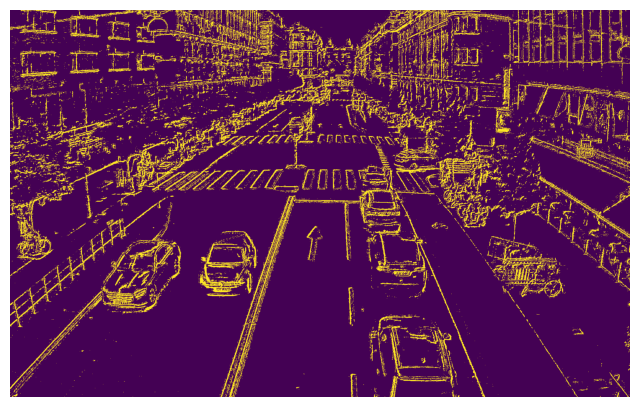

In [18]:
plt.figure(figsize=(8, 8))
plt.imshow(spike_dict[2360])
plt.axis("off")
plt.show()

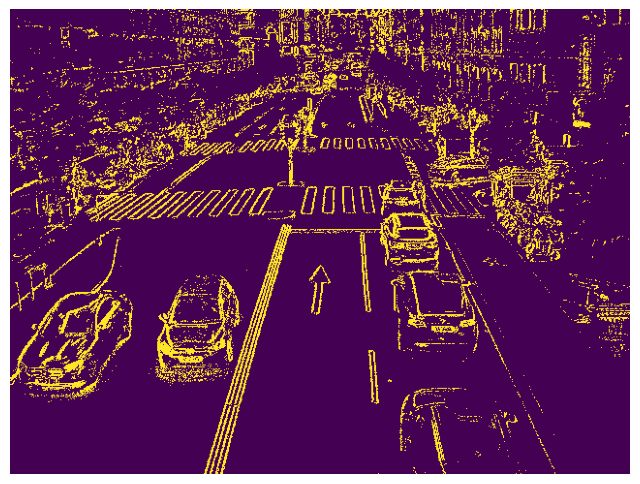

In [19]:
plt.figure(figsize=(8, 8))
plt.imshow(frames[2360])
plt.axis("off")
plt.show()

In [24]:
from skimage import transform
def overlay_binary(frame_binary, overlay, H):

    # warp overlay into frame coordinates
    warped = transform.warp(
        overlay.astype(np.float32),
        H,
        output_shape=frame_binary.shape,
        order=0, 
        preserve_range=True,
        cval=0.0
    )

    overlay_mask = warped > 0.5

    # create RGB output
    h, w = frame_binary.shape
    out = np.zeros((h, w, 3), dtype=np.uint8)

    # frame zeros → white
    out[frame_binary == 1] = [255, 255, 255]

    # overlay ones → red (overrides white)
    out[overlay_mask] = [255, 0, 0]

    return out

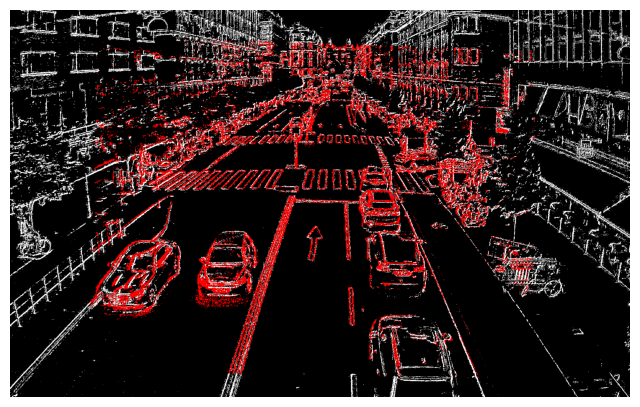

In [25]:
overlay = overlay_binary(spike_dict[2360], frames[2360], H)
plt.figure(figsize=(8, 8))
plt.imshow(overlay)   # overlay is HxWx3
plt.axis("off")
plt.show()